# Part 1, step 3: how much carbon was lost with the forest

Trees store carbon in their trunks, branches and roots. When a forest is cleared, most of that carbon ends up in the air as CO₂. This notebook estimates how much carbon each study country lost with its forest from 2019 to 2022, the same years the deforestation detector was trained on.

The estimate is simple: **area of forest lost × carbon stored per hectare**.

- **Area lost:** Hansen Global Forest Change, at 30 m resolution, for every forest pixel (at least 30% tree cover in 2000) lost in 2019–2022.
- **Carbon per hectare:** NASA/ORNL harmonised biomass carbon map for 2010 (Spawn et al. 2020), counting living carbon above and below ground.

Then it links back to the neural network: for the test areas, how much of the lost carbon sat in patches that the network correctly flagged as lost? Finally, it compares our numbers with Global Forest Watch.

The whole-country totals are computed in 1-degree tiles, and each tile's answer is saved as soon as it arrives, so a stopped run can be restarted without losing work.

## 1. Settings

In [2]:
EE_PROJECT = "earth-01-final"

# Each study country, and the outline names that make it up in the FAO GAUL 2015 boundaries.
# India follows India's own map: GAUL lists Jammu and Kashmir, Arunachal Pradesh and Aksai Chin
# separately, so they are added here.
COUNTRY_PARTS = {
    "Brazil": ["Brazil"],
    "Indonesia": ["Indonesia"],
    "Democratic Republic of the Congo": ["Democratic Republic of the Congo"],
    "India": ["India", "Jammu and Kashmir", "Arunachal Pradesh", "Aksai Chin"],
}
# Rough boxes around each country (west, south, east, north), used to lay out the tiles
COUNTRY_BOX = {
    "Brazil": (-74.5, -34.5, -34.0, 6.0),
    "Indonesia": (94.5, -11.5, 141.5, 6.5),
    "Democratic Republic of the Congo": (12.0, -14.0, 32.0, 6.0),
    "India": (68.0, 6.5, 98.0, 37.5),
}

FIRST_YEAR, LAST_YEAR = 2019, 2022   # same loss window as the training labels
TREECOVER_MIN = 30                   # % canopy in 2000 for a pixel to count as forest
TILE_DEG = 1.0
WORKERS = 8
CO2_PER_C = 44 / 12                  # 1 tonne of carbon becomes 3.67 tonnes of CO2

TILE_CACHE = "../data/raw/part1_carbon_tiles"      # one small file per tile (not committed)
PRED_CSV = "../outputs/part1_test_predictions.csv"  # from notebook 02
GFW_CSV = "../data/cleaned/part1_gfw_check.csv"     # optional, see section 6
OUT_DIR = "../outputs"
HALF_M = 320                                        # half the width of a 640 m patch

## 2. Connect to Earth Engine

In [3]:
import os
import json
import math
import time
from concurrent.futures import ThreadPoolExecutor, as_completed

import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

ee.Authenticate()   # opens a browser sign-in the first time
ee.Initialize(project=EE_PROJECT, opt_url="https://earthengine-highvolume.googleapis.com")
ee.data.setDeadline(180_000)   # give up on any single request after 3 minutes

os.makedirs(TILE_CACHE, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

/opt/anaconda3/lib/python3.13/site-packages/google/api_core/_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.75.1. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## 3. Build the layers

For every 30 m forest pixel lost in 2019–2022, we keep three numbers: its area in hectares, the carbon it held in tonnes, and the year it was lost. Everything else is masked out.

In [4]:
hansen = ee.Image("UMD/hansen/global_forest_change_2023_v1_11")
treecover = hansen.select("treecover2000").unmask(0)   # Hansen hides zeros, so fill them back in
lossyear = hansen.select("lossyear").unmask(0)         # 0 = no loss, 19-22 = 2019-2022
land = hansen.select("datamask").eq(1)
HANSEN_PROJ = hansen.select("lossyear").projection()  # sum on Hansen's own 30 m grid

lost = (lossyear.gte(FIRST_YEAR - 2000).And(lossyear.lte(LAST_YEAR - 2000))
        .And(treecover.gte(TREECOVER_MIN)).And(land))

biomass = ee.ImageCollection("NASA/ORNL/biomass_carbon_density/v1").mosaic()
carbon_per_ha = biomass.select("agb").add(biomass.select("bgb")).unmask(0)   # tonnes of carbon per ha

area_ha = ee.Image.pixelArea().divide(10_000)
stack = (area_ha.rename("loss_ha")
         .addBands(area_ha.multiply(carbon_per_ha).rename("carbon_t"))
         .addBands(lossyear.rename("year"))
         .updateMask(lost))

gaul = ee.FeatureCollection("FAO/GAUL/2015/level0")
outlines = {}
for country, parts in COUNTRY_PARTS.items():
    fc = gaul.filter(ee.Filter.inList("ADM0_NAME", parts))
    found = set(fc.aggregate_array("ADM0_NAME").getInfo())
    missing = [p for p in parts if p not in found]
    if parts[0] in missing:
        raise ValueError(f"'{parts[0]}' not found in GAUL; check the spelling in COUNTRY_PARTS")
    if missing:
        print(f"Note: {missing} not in GAUL, skipped for {country}")
    outlines[country] = fc
print("Layers ready for", ", ".join(outlines))

/opt/anaconda3/lib/python3.13/site-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for UMD/hansen/global_forest_change_2023_v1_11! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by UMD/hansen/global_forest_change_2025_v1_13

Learn more: https://developers.google.com/earth-engine/datasets/catalog/UMD_hansen_global_forest_change_2023_v1_11

  warnings.warn(warning, category=DeprecationWarning)


Layers ready for Brazil, Indonesia, Democratic Republic of the Congo, India


## 4. Add up each country, tile by tile

Each country's box is cut into 1-degree tiles. First the tiles that touch the country are found, and then each tile is summed by year. A tile that is too heavy for one request is split into four smaller tiles. Results are saved to `data/raw/part1_carbon_tiles/` as they arrive, so rerunning this cell only fetches the missing tiles.

Expect this to take a while (very roughly 20–60 minutes) and some Earth Engine time. Watch the usage chart as before.

In [5]:
REDUCER = ee.Reducer.sum().repeat(2).group(groupField=2, groupName="year")

def tiles_for(country):
    w, s, e, n = COUNTRY_BOX[country]
    boxes = [(x, y) for x in np.arange(math.floor(w), math.ceil(e), TILE_DEG)
                    for y in np.arange(math.floor(s), math.ceil(n), TILE_DEG)]
    rects = ee.FeatureCollection([ee.Feature(ee.Geometry.Rectangle([float(x), float(y), float(x + TILE_DEG), float(y + TILE_DEG)]),
                                             {"x": float(x), "y": float(y)}) for x, y in boxes])
    try:   # keep only the tiles that touch the country (a simplified outline is enough here)
        outline = outlines[country].geometry().simplify(2000)
        keep = rects.filterBounds(outline)
        xy = ee.Dictionary({"x": keep.aggregate_array("x"), "y": keep.aggregate_array("y")}).getInfo()
        return list(zip(xy["x"], xy["y"]))
    except Exception as err:
        print(f"{country}: could not pre-filter tiles ({str(err)[:80]}), using all {len(boxes)}")
        return [(float(x), float(y)) for x, y in boxes]

def sum_box(country, x, y, size):
    region = ee.Geometry.Rectangle([x, y, x + size, y + size])
    inside = ee.Image.constant(0).paint(outlines[country], 1).eq(1)
    result = stack.updateMask(inside).reduceRegion(
        reducer=REDUCER, geometry=region, crs=HANSEN_PROJ, maxPixels=1e10, tileScale=4).getInfo()
    out = {}
    for g in result.get("groups", []):
        year = 2000 + int(g["year"])
        out[year] = [out.get(year, [0, 0])[0] + g["sum"][0], out.get(year, [0, 0])[1] + g["sum"][1]]
    return out

def add(a, b):
    for year, (ha, t) in b.items():
        a[year] = [a.get(year, [0, 0])[0] + ha, a.get(year, [0, 0])[1] + t]
    return a

def tile_job(country, x, y, retries=4):
    path = os.path.join(TILE_CACHE, f"{country.replace(' ', '_')}_{x:.1f}_{y:.1f}.json")
    if os.path.exists(path):
        with open(path) as f:
            return country, {int(k): v for k, v in json.load(f).items()}
    for attempt in range(retries):
        try:
            out = sum_box(country, x, y, TILE_DEG)
            break
        except Exception as err:
            if attempt == retries - 1:
                try:   # too heavy: split into four smaller tiles
                    out, half = {}, TILE_DEG / 2
                    for dx in (0, half):
                        for dy in (0, half):
                            out = add(out, sum_box(country, x + dx, y + dy, half))
                except Exception as err2:
                    print(f"{country} tile {x},{y} failed: {str(err2)[:120]}")
                    return country, None
            else:
                time.sleep(2 ** attempt)
    with open(path, "w") as f:
        json.dump(out, f)
    return country, out

jobs_list = [(c, x, y) for c in COUNTRY_PARTS for x, y in tiles_for(c)]
print(f"{len(jobs_list)} tiles to add up")
totals, failed = {c: {} for c in COUNTRY_PARTS}, 0
with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    jobs = [pool.submit(tile_job, *j) for j in jobs_list]
    for job in tqdm(as_completed(jobs), total=len(jobs)):
        country, out = job.result()
        if out is None:
            failed += 1
        else:
            add(totals[country], out)
if failed:
    print(f"Warning: {failed} tiles failed. Rerun this cell to fetch just those; totals below are incomplete.")

1866 tiles to add up


  0%|          | 0/1866 [00:00<?, ?it/s]

## 5. Results by country and year

Forest lost and carbon released, 2019-2022
                                      loss_ha        carbon_t  co2_Mt  carbon_t_per_ha
country                                                                               
Brazil                           12,313,932.9 1,162,584,141.7 4,262.8             94.4
Democratic Republic of the Congo  4,999,051.2   436,058,773.2 1,598.9             87.2
Indonesia                         3,846,862.5   407,972,421.8 1,495.9            106.1
India                               516,126.9    37,286,172.7   136.7             72.2


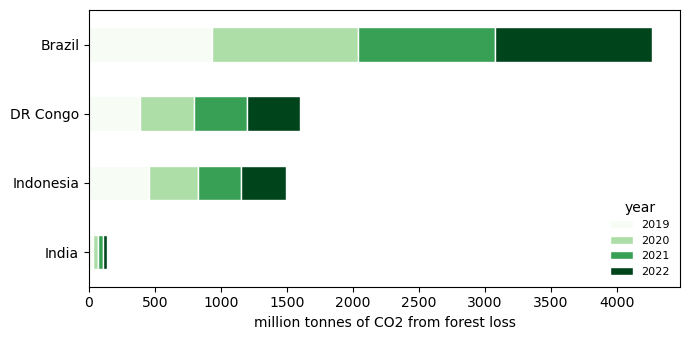

In [10]:
rows = [{"country": c, "year": year, "loss_ha": ha, "carbon_t": t}
        for c, by_year in totals.items() for year, (ha, t) in sorted(by_year.items())]
carbon = pd.DataFrame(rows)
carbon["co2_Mt"] = carbon["carbon_t"] * CO2_PER_C / 1e6
carbon["carbon_t_per_ha"] = carbon["carbon_t"] / carbon["loss_ha"]
carbon.to_csv(os.path.join(OUT_DIR, "part1_carbon_by_country.csv"), index=False)

summary = carbon.groupby("country")[["loss_ha", "carbon_t", "co2_Mt"]].sum()
summary["carbon_t_per_ha"] = summary["carbon_t"] / summary["loss_ha"]
summary = summary.sort_values("co2_Mt", ascending=False)
pd.set_option("display.float_format", "{:,.1f}".format)
print(f"Forest lost and carbon released, {FIRST_YEAR}-{LAST_YEAR}")
print(summary.to_string())

fig, ax = plt.subplots(figsize=(7, 3.5))
pivot = carbon.pivot(index="country", columns="year", values="co2_Mt").loc[summary.index]
pivot.plot.barh(stacked=True, ax=ax, colormap="Greens", edgecolor="white")
ax.set_xlabel("million tonnes of CO2 from forest loss"); ax.set_ylabel("")
ax.set_yticklabels(["DR Congo" if len(t.get_text()) > 20 else t.get_text() for t in ax.get_yticklabels()])
ax.invert_yaxis(); ax.legend(title="year", fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part1_carbon_by_country.png"), dpi=150)
plt.show()

## 6. Link to the neural network: carbon in the test patches

For every test patch from notebook 02, we add up the carbon lost inside its 640 m square. That shows how much of the lost carbon the network's "lost" calls covered, and how much sat in the patches it missed. A miss on a patch with a lot of carbon matters more than a miss on a patch with very little.

In [11]:
pred = pd.read_csv(PRED_CSV)
squares = [ee.Feature(ee.Geometry.Point([r.lon, r.lat]).buffer(HALF_M).bounds(), {"patch_id": r.patch_id})
           for r in pred.itertuples()]
patch_rows = []
for s in tqdm(range(0, len(squares), 200)):
    fc = ee.FeatureCollection(squares[s:s + 200])
    for attempt in range(4):
        try:
            res = stack.select(["loss_ha", "carbon_t"]).unmask(0).reduceRegions(
                collection=fc, reducer=ee.Reducer.sum(), crs=HANSEN_PROJ).getInfo()
            break
        except Exception as err:
            if attempt == 3:
                raise
            time.sleep(2 ** attempt)
    patch_rows += [f["properties"] for f in res["features"]]
pred = pred.merge(pd.DataFrame(patch_rows), on="patch_id")

pred["outcome"] = np.select(
    [(pred.label == 1) & (pred.predicted == 1), (pred.label == 1) & (pred.predicted == 0),
     (pred.label == 0) & (pred.predicted == 1)],
    ["lost, caught", "lost, missed", "stable, false alarm"], "stable, correct")
by_outcome = pred.groupby(["country", "outcome"])[["carbon_t"]].sum().unstack(fill_value=0)["carbon_t"]
truly_lost = by_outcome.get("lost, caught", 0) + by_outcome.get("lost, missed", 0)
share_caught = by_outcome.get("lost, caught", 0) / truly_lost
overall = pred.loc[pred.outcome == "lost, caught", "carbon_t"].sum() / pred.loc[pred.label == 1, "carbon_t"].sum()

print(f"The network's 'lost' calls covered {overall:.1%} of the carbon lost in the test patches")
print((share_caught * 100).round(1).rename("% of lost carbon caught").to_string())
print("\nCarbon (tonnes) per outcome:")
print(by_outcome.round(0).to_string())

missed = pred[pred.outcome == "lost, missed"]
caught = pred[pred.outcome == "lost, caught"]
print(f"\nAverage lost area in caught patches {caught.loss_ha.mean():.1f} ha, in missed patches {missed.loss_ha.mean():.1f} ha")

  0%|          | 0/6 [00:00<?, ?it/s]

The network's 'lost' calls covered 96.0% of the carbon lost in the test patches
country
Brazil                             97.9
Democratic Republic of the Congo   96.3
India                              75.1
Indonesia                          97.2

Carbon (tonnes) per outcome:
outcome                           lost, caught  lost, missed  stable, correct  stable, false alarm
country                                                                                           
Brazil                               374,493.0       7,848.0            199.0                 31.0
Democratic Republic of the Congo      82,106.0       3,182.0            822.0                  0.0
India                                 40,502.0      13,459.0            133.0                 19.0
Indonesia                            280,445.0       8,084.0            493.0                138.0

Average lost area in caught patches 17.7 ha, in missed patches 8.1 ha


## 7. Check against Global Forest Watch

Global Forest Watch publishes yearly tree cover loss and emissions for every country. Their **loss area** uses the same Hansen data, so it should be close to ours. The small differences come from country borders and versions. Their **emissions** use a different carbon map and also count other greenhouse gases and soil, so expect those to differ more.

To add the check, open each country's dashboard (globalforestwatch.org → Dashboards → country). Set canopy density to 30% and write the yearly numbers for 2019–2022 into `data/cleaned/part1_gfw_check.csv` with these columns:

`country,year,gfw_loss_ha,gfw_emissions_MtCO2e`

The country names must match the ones above. If the file isn't there, this cell just says so.

In [12]:
if os.path.exists(GFW_CSV):
    gfw = pd.read_csv(GFW_CSV)
    check = carbon.merge(gfw, on=["country", "year"], how="inner")
    check["loss_diff_%"] = 100 * (check["loss_ha"] - check["gfw_loss_ha"]) / check["gfw_loss_ha"]
    check["co2_diff_%"] = 100 * (check["co2_Mt"] - check["gfw_emissions_MtCO2e"]) / check["gfw_emissions_MtCO2e"]
    print(check[["country", "year", "loss_ha", "gfw_loss_ha", "loss_diff_%",
                 "co2_Mt", "gfw_emissions_MtCO2e", "co2_diff_%"]].to_string(index=False))
else:
    check = None
    print(f"No {GFW_CSV} yet, so the Global Forest Watch check is skipped.")

                         country  year     loss_ha  gfw_loss_ha  loss_diff_%  co2_Mt  gfw_emissions_MtCO2e  co2_diff_%
                          Brazil  2019 2,702,282.5  2,693,011.8          0.3   928.0                   NaN         NaN
                          Brazil  2020 3,297,436.7  3,286,618.5          0.3 1,108.1                   NaN         NaN
                          Brazil  2021 2,998,420.5  2,985,832.2          0.4 1,042.2                   NaN         NaN
                          Brazil  2022 3,315,793.2  3,303,933.8          0.4 1,184.6                   NaN         NaN
                       Indonesia  2019 1,170,615.4  1,175,420.1         -0.4   454.8                   NaN         NaN
                       Indonesia  2020   956,743.8    960,275.9         -0.4   371.3                   NaN         NaN
                       Indonesia  2021   837,635.6    839,695.2         -0.2   322.2                   NaN         NaN
                       Indonesia  2022   881,867

In [13]:
# Save everything the website needs in one small file
result = {
    "years": [FIRST_YEAR, LAST_YEAR],
    "method": "Hansen GFC v1.11 loss (>=30% canopy in 2000) x NASA/ORNL 2010 above+below-ground biomass carbon",
    "by_country": {c: {"loss_ha": float(r.loss_ha), "carbon_t": float(r.carbon_t), "co2_Mt": float(r.co2_Mt),
                       "carbon_t_per_ha": float(r.carbon_t_per_ha)} for c, r in summary.iterrows()},
    "by_country_year": carbon.to_dict(orient="records"),
    "cnn_test_patches": {"share_of_lost_carbon_caught": float(overall),
                         "by_country": {c: float(v) for c, v in share_caught.items()}},
    "gfw_check": None if check is None else check.to_dict(orient="records"),
    "tiles_failed": failed,
}
with open(os.path.join(OUT_DIR, "part1_carbon_summary.json"), "w") as f:
    json.dump(result, f, indent=2)
print("Saved", os.path.join(OUT_DIR, "part1_carbon_summary.json"))

Saved ../outputs/part1_carbon_summary.json


## 8. What these numbers do and don't show

- **These are gross losses.** They count carbon released when forest is cleared, not carbon taken back up by regrowth. A country's net forest carbon balance can be smaller.
- **Committed, not instant.** The figure assumes all living carbon in the lost trees is released. In reality some is released over years, and some is stored in wood products.
- **The carbon map is from 2010.** Forests may have grown or been degraded before they were cleared in 2019–2022.
- **The carbon map is coarse (300 m).** Each 30 m lost pixel takes the average carbon of its 300 m cell, which may include fields or roads. This probably underestimates the carbon in dense forest.
- **"Tree cover loss" is not only deforestation.** Hansen counts fires, storms and plantation harvests as well as permanent clearing.
- **The network link uses the test patches only.** It shows how well the detector's calls line up with carbon. It isn't a whole-country estimate made by the network.

## Sources and credits

- Hansen, M. C. et al. (2013), *High-Resolution Global Maps of 21st-Century Forest Cover Change*, Science 342, v1.11 (CC BY 4.0).
- Spawn, S. A., Sullivan, C. C., Lark, T. J. and Gibbs, H. K. (2020), *Harmonized global maps of above and belowground biomass carbon density in the year 2010*, Scientific Data 7, 112. NASA/ORNL DAAC, doi:10.3334/ORNLDAAC/1763 (public domain).
- FAO GAUL 2015 country boundaries, used only to add up totals.
- Global Forest Watch (globalforestwatch.org), used only as a check (CC BY 4.0).